In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

In [2]:
start = '2012-01-01'
end = '2025-01-01'
stock = 'GOOG'

data = yf.download(stock, start, end)

[*********************100%***********************]  1 of 1 completed


In [3]:
data.reset_index(inplace=True)

In [4]:
data

Price,Date,Close,High,Low,Open,Volume
Ticker,,GOOG,GOOG,GOOG,GOOG,GOOG
0,2012-01-03,16.417629,16.485234,16.095893,16.109958,147611217
1,2012-01-04,16.488438,16.537044,16.299443,16.408251,114989399
2,2012-01-05,16.259720,16.382098,16.191129,16.336700,131808205
3,2012-01-06,16.037912,16.284148,16.032236,16.263175,108119746
4,2012-01-09,15.357924,15.963399,15.327576,15.951061,233776981
...,...,...,...,...,...,...
3265,2024-12-24,196.419479,196.518888,194.061283,195.027623,6809800
3266,2024-12-26,195.952240,197.006065,194.729392,195.594336,7907900
3267,2024-12-27,192.910019,195.653956,190.854069,195.325876,14693000


In [5]:
mavg_100_days = data.Close.rolling(100).mean()

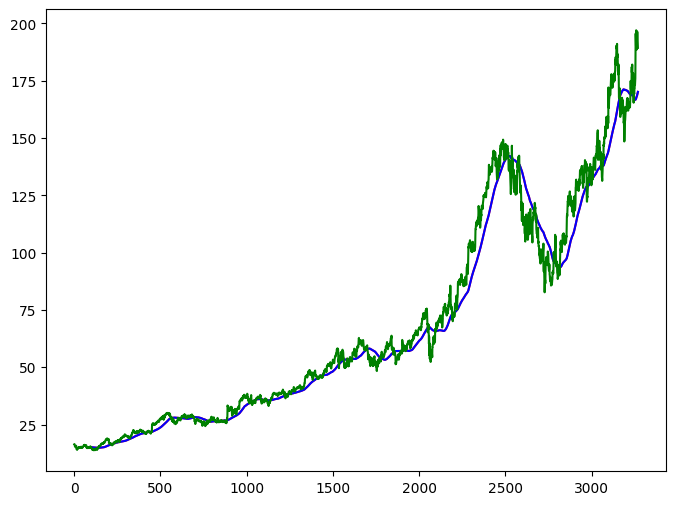

In [6]:
plt.figure(figsize=(8,6))
plt.plot(mavg_100_days, 'r')
plt.plot(mavg_100_days, 'b')
plt.plot(data.Close, 'g')
plt.show()

In [7]:
mavg_200_days = data.Close.rolling(200).mean()

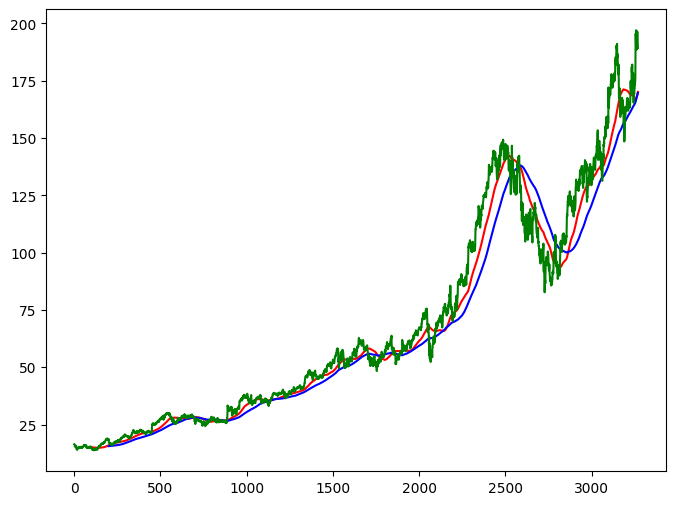

In [8]:
plt.figure(figsize=(8,6))
plt.plot(mavg_100_days, 'r')
plt.plot(mavg_200_days, 'b')
plt.plot(data.Close, 'g')
plt.show()

In [9]:
data.dropna(inplace=True)

In [10]:
data_train = pd.DataFrame(data.Close[0: int(len(data)*0.80)])
data_test = pd.DataFrame(data.Close[int(len(data)*0.80): len(data)])

In [11]:
data_train.shape[0]

2616

In [12]:
data_test.shape[0]

654

In [13]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))

In [14]:
data_train_scale = scaler.fit_transform(data_train)

In [15]:
x = []
y =[]

for i in range(100, data_train_scale.shape[0]):
    x.append(data_train_scale[i-100:i])
    y.append(data_train_scale[i,0])

In [16]:
x, y = np.array(x), np.array(y)

In [17]:
from tensorflow.keras.layers import Dense, Dropout, LSTM, Input
from tensorflow.keras.models import Sequential

In [18]:
model = Sequential()
model.add(Input(shape=(x_train.shape[1], 1)))
model.add(LSTM(units = 50, activation = 'relu', return_sequences = True, input_shape = ((x.shape[1],1))))
model.add(Dropout(0.2))

model.add(LSTM(units = 60, activation= 'relu', return_sequences = True))
model.add(Dropout(0.3))

model.add(LSTM(units = 80, activation = 'relu', return_sequences = True))
model.add(Dropout(0.4))

model.add(LSTM(units = 120, activation = 'relu'))
model.add(Dropout(0.5))

model.add(Dense(units= 1))

NameError: name 'x_train' is not defined

In [ ]:
model.compile(optimizer = 'adam', loss = 'mean_squared_error')

In [ ]:
model.fit(x,y, epochs = 50, batch_size = 32, verbose = 1)